In [3]:
import pandas as pd
import os
import time
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import optuna
from optuna.samplers import TPESampler

from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

In [4]:
df = pd.read_csv('speeches_processed.csv')

In [5]:
DATE_COL = "date"

df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df["year"] = df[DATE_COL].dt.year

BENCH_YEARS = [2015, 2021]
df_bench = df[df["year"].isin(BENCH_YEARS)].copy().reset_index(drop=True)

In [6]:
# ---------------- Configuração (fixar ANTES de ver resultados) ----------------
SEED = 42

VARIANTS = {
    "base":          "speech_no_custom_stopwords",
    "lemma":         "speech_lemmatized",
    "stemmed":  "speech_stemmed",   
}

# Espaço de procura
SPACE = {
    "n_components":     (5, 50, 5),               # int, passo 5
    "max_df":           [0.5, 0.7, 0.9],          # categórico (facilita a cache)
    "doc_topic_prior":  (0.01, 1.0),              # float, escala log
    "topic_word_prior": (0.001, 0.5),             # float, escala log
}

MIN_DF = 10              # rever depois de ver o tamanho do vocabulário
MIN_TOKENS = 20          # rever depois de ver quantos documentos se perdem
MAX_DOCS = None          # df_bench já são os 2 anos, não é preciso amostrar
MAX_ITER_SEARCH = 10     # fase de procura
MAX_ITER_FINAL = 30      # fase de confirmação
TOP_N = 10               # palavras por tópico
N_TRIALS = 40            # igual para todas as variantes
TOP_K = 5                # configs a confirmar por variante
N_SEEDS = 5              # seeds no re-treino
COH_DOCS = 10000         # docs usados no c_v (None = todos); fixo em todas as tentativas

TEST_SIZE = 0.2
VAL_SIZE = 0.2           # fração do conjunto restante (treino+val)

RESULTS_DIR = "lda_bayes"
os.makedirs(RESULTS_DIR, exist_ok=True)
optuna.logging.set_verbosity(optuna.logging.WARNING)


# ---------------- Funções auxiliares ----------------
def to_text(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        return " ".join(map(str, x))
    return "" if pd.isna(x) else str(x)


def topic_diversity(topics):
    words = [w for t in topics for w in t]
    return len(set(words)) / len(words)


def top_words(lda, names, n=TOP_N):
    return [[names[i] for i in comp.argsort()[::-1][:n]] for comp in lda.components_]


# ---------------- Preparação dos dados ----------------
def prepare_data(df, variants=VARIANTS):
    data = df.sample(MAX_DOCS, random_state=SEED) if MAX_DOCS else df
    texts = {v: data[c].apply(to_text) for v, c in variants.items()}

    # mesmo conjunto de documentos em todas as variantes
    keep = np.all([t.str.split().str.len() >= MIN_TOKENS for t in texts.values()], axis=0)
    texts = {v: t[keep] for v, t in texts.items()}
    idx = next(iter(texts.values())).index
    print(f"{len(idx)} documentos usados ({(~keep).sum()} removidos por serem curtos)")

    # split treino / validação / teste (iguais para todas as variantes)
    trainval_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=SEED)
    train_idx, val_idx = train_test_split(trainval_idx, test_size=VAL_SIZE, random_state=SEED)
    print(f"treino={len(train_idx)}  validação={len(val_idx)}  teste={len(test_idx)}")

    # guarda os índices para reprodutibilidade
    json.dump({"train": [int(i) for i in train_idx],
               "val":   [int(i) for i in val_idx],
               "test":  [int(i) for i in test_idx]},
              open(f"{RESULTS_DIR}/splits.json", "w"))

    return texts, train_idx, val_idx, test_idx


texts, train_idx, val_idx, test_idx = prepare_data(df_bench)

82424 documentos usados (10254 removidos por serem curtos)
treino=52751  validação=13188  teste=16485


In [9]:
ctx = VariantContext("base")

t0 = time.time()
X, names, val_toks, dic = ctx.get(0.5)
print(f"vetorização: {time.time()-t0:.0f}s | X={X.shape} | tokens (validação)={sum(map(len, val_toks)):,}")

# LDA: 5000 docs, 2 iterações, comparar n_jobs=1 vs -1
for nj in (1, -1):
    t0 = time.time()
    lda = LatentDirichletAllocation(n_components=50, max_iter=2, learning_method="online",
                                    random_state=SEED, n_jobs=nj).fit(X[:5000])
    t = time.time() - t0
    full = t * (X.shape[0] / 5000) * (MAX_ITER_SEARCH / 2)
    print(f"LDA n_jobs={nj}: {t:.0f}s -> estimativa treino completo ≈ {full/60:.0f} min")

# c_v: 1000 docs de validação
topics = top_words(lda, names)
t0 = time.time()
CoherenceModel(topics=topics, texts=val_toks[:1000], dictionary=dic,
               coherence="c_v", processes=1).get_coherence()
t = time.time() - t0
print(f"c_v (1000 docs): {t:.0f}s -> estimativa com {len(val_toks)} docs ≈ {t*len(val_toks)/1000/60:.0f} min")

vetorização: 4s | X=(40000, 11646) | tokens (validação)=774,714
LDA n_jobs=1: 11s -> estimativa treino completo ≈ 8 min
LDA n_jobs=-1: 27s -> estimativa treino completo ≈ 18 min


c:\Users\rafae\Documents\GitHub\Dissertacao_UE\venv312\Lib\site-packages\gensim\topic_coherence\direct_confirmation_measure.py:204: RuntimeWarning: divide by zero encountered in scalar divide
  m_lr_i = np.log(numerator / denominator)
c:\Users\rafae\Documents\GitHub\Dissertacao_UE\venv312\Lib\site-packages\gensim\topic_coherence\indirect_confirmation_measure.py:323: RuntimeWarning: invalid value encountered in scalar divide
  return cv1.T.dot(cv2)[0, 0] / (_magnitude(cv1) * _magnitude(cv2))


c_v (1000 docs): 2s -> estimativa com 10000 docs ≈ 0 min


In [8]:
# ---------------- Configuração adicional ----------------
TRAIN_DOCS_SEARCH = 40000   # subamostra fixa do treino na procura (None = treino completo)


# ---------------- Conjuntos usados na procura (iguais em todas as variantes) ----------------
def build_search_sets():
    rng = np.random.RandomState(SEED)
    tr = np.asarray(train_idx)
    if TRAIN_DOCS_SEARCH and TRAIN_DOCS_SEARCH < len(tr):
        tr = rng.choice(tr, TRAIN_DOCS_SEARCH, replace=False)
    va = np.asarray(val_idx)
    if COH_DOCS and COH_DOCS < len(va):
        va = rng.choice(va, COH_DOCS, replace=False)
    return tr, va

search_train_idx, coh_val_idx = build_search_sets()
print(f"procura: {len(search_train_idx)} docs de treino | c_v em {len(coh_val_idx)} docs de validação")


# ---------------- Contexto por variante (vetorização em cache) ----------------
class VariantContext:
    """Vetorizador ajustado SÓ no treino; c_v calculado em documentos de validação."""
    def __init__(self, vname):
        self.vname = vname
        self.train_docs = texts[vname].loc[search_train_idx].tolist()
        self.val_docs = texts[vname].loc[coh_val_idx].tolist()
        self.cache = {}

    def get(self, max_df):
        if max_df not in self.cache:
            vec = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                  min_df=MIN_DF, max_df=max_df)
            X = vec.fit_transform(self.train_docs)
            names = vec.get_feature_names_out()
            vocab = set(names)
            val_toks = [[w for w in d.split() if w in vocab] for d in self.val_docs]
            dic = Dictionary([list(names)])
            self.cache[max_df] = (X, names, val_toks, dic)
        return self.cache[max_df]


def fit_and_score(ctx, cfg, max_iter, seed=SEED):
    X, names, val_toks, dic = ctx.get(cfg["max_df"])
    t0 = time.time()
    lda = LatentDirichletAllocation(
        n_components=cfg["n_components"],
        doc_topic_prior=cfg["doc_topic_prior"],
        topic_word_prior=cfg["topic_word_prior"],
        max_iter=max_iter, learning_method="online",
        random_state=seed, n_jobs=1).fit(X)
    t_fit = time.time() - t0

    topics = top_words(lda, names)
    t1 = time.time()
    c_v = CoherenceModel(topics=topics, texts=val_toks, dictionary=dic,
                         coherence="c_v", processes=1).get_coherence()
    return {"c_v": c_v, "diversidade": topic_diversity(topics), "vocab": len(names),
            "t_fit": round(t_fit, 1), "t_coh": round(time.time() - t1, 1)}


# ---------------- Medir o tempo de uma tentativa (pior caso) ----------------
def time_one_trial(vname="base", n_components=50, max_df=0.5):
    ctx = VariantContext(vname)
    t0 = time.time()
    ctx.get(max_df)
    t_vec = time.time() - t0
    res = fit_and_score(ctx, {"n_components": n_components, "max_df": max_df,
                              "doc_topic_prior": 0.1, "topic_word_prior": 0.01},
                        MAX_ITER_SEARCH)
    per_trial = res["t_fit"] + res["t_coh"]
    total_h = per_trial * N_TRIALS * len(VARIANTS) / 3600
    print(f"vetorização: {t_vec:.0f}s (uma vez por variante e max_df) | vocab={res['vocab']}")
    print(f"LDA: {res['t_fit']}s | c_v: {res['t_coh']}s | c_v={res['c_v']:.3f}")
    print(f"estimativa (pior caso, K={n_components}): {total_h:.1f} h para {N_TRIALS} tentativas x {len(VARIANTS)} variantes")
    return res


# ---------------- Objetivo e procura ----------------
def make_objective(ctx):
    def objective(trial):
        cfg = {
            "n_components":     trial.suggest_int("n_components", *SPACE["n_components"][:2],
                                                  step=SPACE["n_components"][2]),
            "max_df":           trial.suggest_categorical("max_df", SPACE["max_df"]),
            "doc_topic_prior":  trial.suggest_float("doc_topic_prior", *SPACE["doc_topic_prior"], log=True),
            "topic_word_prior": trial.suggest_float("topic_word_prior", *SPACE["topic_word_prior"], log=True),
        }
        res = fit_and_score(ctx, cfg, MAX_ITER_SEARCH)
        for k in ("diversidade", "vocab", "t_fit", "t_coh"):
            trial.set_user_attr(k, res[k])
        return res["c_v"]
    return objective


def save_csv(study, trial):
    study.trials_dataframe().to_csv(f"{RESULTS_DIR}/trials_{study.study_name}.csv", index=False)


def run_search(variants=VARIANTS, n_trials=N_TRIALS, timeout=None):
    studies = {}
    for vname in variants:
        ctx = VariantContext(vname)
        study = optuna.create_study(
            direction="maximize",
            sampler=TPESampler(seed=SEED, n_startup_trials=10),
            storage=f"sqlite:///{RESULTS_DIR}/lda_optuna.db",
            study_name=f"lda_{vname}",
            load_if_exists=True)

        done = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
        remaining = n_trials - done
        if remaining > 0:
            study.optimize(make_objective(ctx), n_trials=remaining, timeout=timeout,
                           callbacks=[save_csv], show_progress_bar=True, n_jobs=1)

        studies[vname] = study
        print(f"[{vname}] melhor c_v={study.best_value:.3f} | {study.best_params}")
        del ctx
    return studies


# 1) Primeiro mede o tempo e decide se TRAIN_DOCS_SEARCH / N_TRIALS estão bem:
#time_one_trial()

# 2) Depois lança a procura:
studies = run_search()

procura: 40000 docs de treino | c_v em 10000 docs de validação


Best trial: 37. Best value: 0.565848: 100%|██████████| 40/40 [1:28:50<00:00, 133.27s/it]


[base] melhor c_v=0.566 | {'n_components': 40, 'max_df': 0.9, 'doc_topic_prior': 0.03859807682004263, 'topic_word_prior': 0.3892850369447975}


Best trial: 32. Best value: 0.540401: 100%|██████████| 40/40 [1:17:23<00:00, 116.09s/it]


[lemma] melhor c_v=0.540 | {'n_components': 20, 'max_df': 0.5, 'doc_topic_prior': 0.528090584822178, 'topic_word_prior': 0.014165780264331048}


Best trial: 33. Best value: 0.541268: 100%|██████████| 40/40 [1:55:14<00:00, 172.86s/it]

[stemmed] melhor c_v=0.541 | {'n_components': 30, 'max_df': 0.9, 'doc_topic_prior': 0.4921817949502647, 'topic_word_prior': 0.003356652441522145}


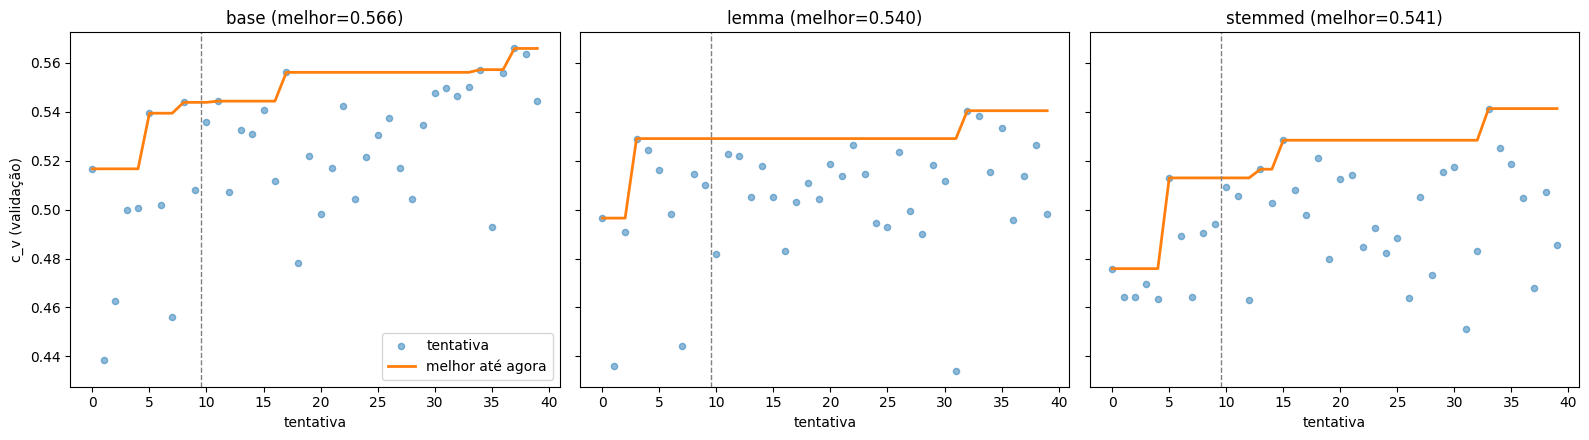

base: melhor nas 30 primeiras=0.556 | melhor nas 40=0.566 | ganho das últimas 10=+0.010
lemma: melhor nas 30 primeiras=0.529 | melhor nas 40=0.540 | ganho das últimas 10=+0.011
stemmed: melhor nas 30 primeiras=0.528 | melhor nas 40=0.541 | ganho das últimas 10=+0.013


In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, vname in zip(axes, VARIANTS):
    t = pd.read_csv(f"{RESULTS_DIR}/trials_lda_{vname}.csv")
    t = t[t["state"] == "COMPLETE"].sort_values("number")
    ax.scatter(t["number"], t["value"], s=20, alpha=0.5, label="tentativa")
    ax.plot(t["number"], t["value"].cummax(), lw=2, color="C1", label="melhor até agora")
    ax.axvline(9.5, ls="--", c="gray", lw=1)          # fim das 10 tentativas aleatórias
    ax.set_title(f"{vname} (melhor={t['value'].max():.3f})")
    ax.set_xlabel("tentativa")
axes[0].set_ylabel("c_v (validação)")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/convergencia.png", dpi=200)
plt.show()

# Tabela de apoio: o melhor ainda melhorava no fim?
for vname in VARIANTS:
    t = pd.read_csv(f"{RESULTS_DIR}/trials_lda_{vname}.csv").sort_values("number")
    v = t["value"].to_numpy()
    print(f"{vname}: melhor nas 30 primeiras={v[:30].max():.3f} | "
          f"melhor nas 40={v.max():.3f} | ganho das últimas 10={v.max()-v[:30].max():+.3f}")

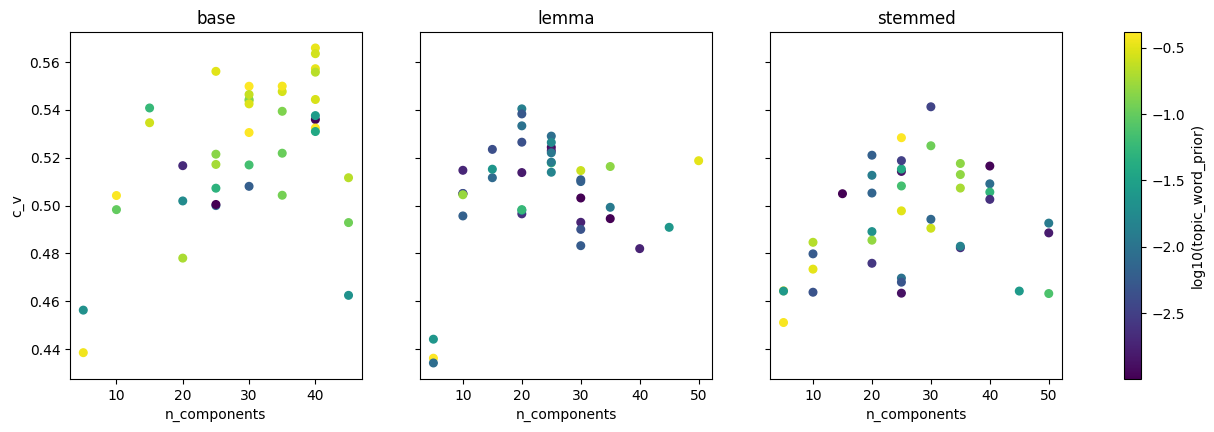

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, vname in zip(axes, VARIANTS):
    t = pd.read_csv(f"{RESULTS_DIR}/trials_lda_{vname}.csv")
    sc = ax.scatter(t["params_n_components"], t["value"], c=np.log10(t["params_topic_word_prior"]),
                    cmap="viridis", s=30)
    ax.set_title(vname); ax.set_xlabel("n_components")
axes[0].set_ylabel("c_v")
fig.colorbar(sc, ax=axes, label="log10(topic_word_prior)")
plt.show()

In [12]:
studies = run_search(n_trials=60)

Best trial: 45. Best value: 0.577512: 100%|██████████| 20/20 [1:12:31<00:00, 217.59s/it]


[base] melhor c_v=0.578 | {'n_components': 40, 'max_df': 0.9, 'doc_topic_prior': 0.05238574150953151, 'topic_word_prior': 0.4608435513152719}


Best trial: 46. Best value: 0.54508: 100%|██████████| 20/20 [20:46<00:00, 62.35s/it]


[lemma] melhor c_v=0.545 | {'n_components': 20, 'max_df': 0.7, 'doc_topic_prior': 0.5407964883778792, 'topic_word_prior': 0.0154631569730269}


Best trial: 41. Best value: 0.542641: 100%|██████████| 20/20 [28:01<00:00, 84.08s/it]

[stemmed] melhor c_v=0.543 | {'n_components': 20, 'max_df': 0.9, 'doc_topic_prior': 0.6132052286566178, 'topic_word_prior': 0.0034795434794477227}


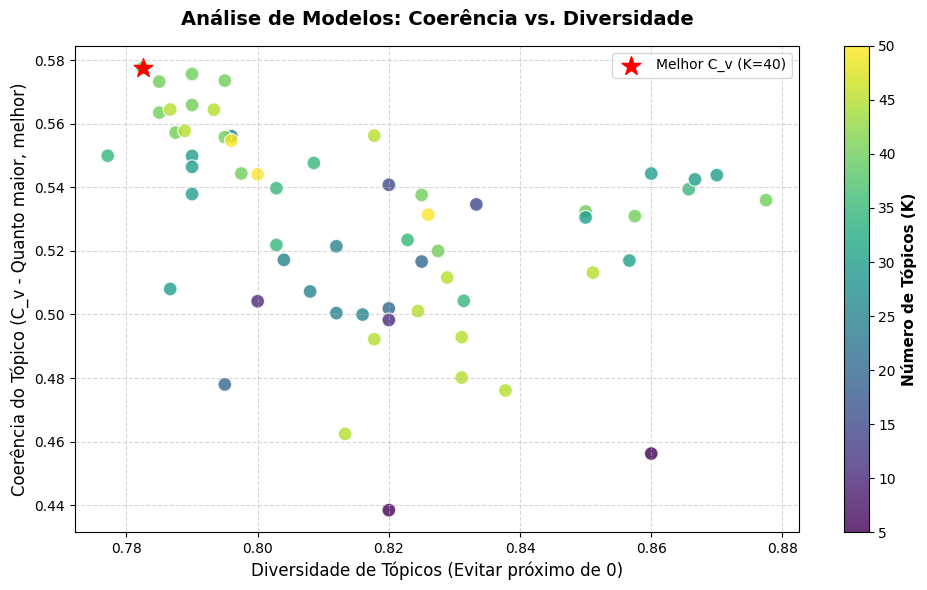

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_trials_analysis(csv_path):
    # 1. Carregar e filtrar dados
    df = pd.read_csv(csv_path)
    df = df[df["state"] == "COMPLETE"]
    
    # Adaptar os nomes das colunas geradas automaticamente pelo Optuna
    # O Optuna guarda user_attrs com o prefixo 'user_attrs_'
    cv_col = "value" # O objetivo principal que retornou (c_v)
    diversity_col = "user_attrs_diversidade"
    k_col = "params_n_components"
    
    plt.figure(figsize=(10, 6))
    
    # 2. Criar o gráfico de dispersão
    scatter = plt.scatter(
        df[diversity_col], 
        df[cv_col], 
        c=df[k_col], 
        cmap="viridis", 
        s=100, 
        alpha=0.8,
        edgecolors="w"
    )
    
    # 3. Adicionar barra de cores (indica o número de tópicos K)
    cbar = plt.colorbar(scatter)
    cbar.set_label("Número de Tópicos (K)", fontsize=11, fontweight="bold")
    
    # 4. Detalhes estéticos
    plt.title("Análise de Modelos: Coerência vs. Diversidade", fontsize=14, fontweight="bold", pad=15)
    plt.xlabel("Diversidade de Tópicos (Evitar próximo de 0)", fontsize=12)
    plt.ylabel("Coerência do Tópico (C_v - Quanto maior, melhor)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    
    # Destacar a melhor tentativa (Maior C_v)
    best_trial = df.loc[df[cv_col].idxmax()]
    plt.scatter(
        best_trial[diversity_col], 
        best_trial[cv_col], 
        color="red", 
        s=200, 
        marker="*", 
        label=f"Melhor C_v (K={int(best_trial[k_col])})"
    )
    plt.legend()
    
    plt.tight_layout()
    plt.show()

# Para correr (substitua pelo caminho correto do seu ficheiro):
plot_trials_analysis(f"{"lda_bayes"}/trials_lda_base.csv")


In [14]:
def inspect_top_trial_topics(csv_path, ctx, top_n_words=10, rank=0):
    """
    Treina rapidamente o modelo de uma das melhores tentativas para inspecionar os tópicos.
    rank=0 traz o melhor modelo, rank=1 o segundo melhor, etc.
    """
    df = pd.read_csv(csv_path)
    df = df[df["state"] == "COMPLETE"].sort_values(by="value", ascending=False)
    
    # Selecionar a linha com base no rank desejado
    trial_row = df.iloc[rank]
    
    cfg = {
        "n_components": int(trial_row["params_n_components"]),
        "max_df": float(trial_row["params_max_df"]) if isinstance(trial_row["params_max_df"], (int, float)) else trial_row["params_max_df"],
        "doc_topic_prior": float(trial_row["params_doc_topic_prior"]),
        "topic_word_prior": float(trial_row["params_topic_word_prior"])
    }
    
    print(f"--- Inspecionando Rank {rank+1} ---")
    print(f"Parâmetros: K={cfg['n_components']}, max_df={cfg['max_df']}, alpha={cfg['doc_topic_prior']:.3f}, beta={cfg['topic_word_prior']:.3f}")
    print(f"Métricas originais -> C_v: {trial_row['value']:.3f} | Diversidade: {trial_row['user_attrs_diversidade']:.3f}\n")
    
    # Recuperar dados do cache do seu VariantContext
    X, names, _, _ = ctx.get(cfg["max_df"])
    
    # Treinar o modelo desta tentativa específica
    from sklearn.decomposition import LatentDirichletAllocation
    lda = LatentDirichletAllocation(
        n_components=cfg["n_components"],
        doc_topic_prior=cfg["doc_topic_prior"],
        topic_word_prior=cfg["topic_word_prior"],
        max_iter=10, # iterações rápidas apenas para inspeção
        learning_method="online",
        random_state=42, n_jobs=-1
    ).fit(X)
    
    # Imprimir as palavras-chave de cada tópico
    for topic_idx, topic in enumerate(lda.components_):
        top_words_idx = topic.argsort()[:-top_n_words - 1:-1]
        top_words = [names[i] for i in top_words_idx]
        print(f"Tópico #{topic_idx + 1}: {', '.join(top_words)}")

# Exemplo de uso:
inspect_top_trial_topics(f"{"lda_bayes"}/trials_lda_base.csv", ctx=VariantContext("base"), rank=0)


--- Inspecionando Rank 1 ---
Parâmetros: K=40, max_df=0.9, alpha=0.052, beta=0.461
Métricas originais -> C_v: 0.578 | Diversidade: 0.782

Tópico #1: fisheries, fishing, agreement, resources, sea, sustainable, vessels, marine, management, fish
Tópico #2: russia, ukraine, political, policy, country, countries, russian, foreign, eastern, economic
Tópico #3: immunity, office, proceedings, prosecutor, alleged, waiver, parliamentary, duties, voted, criminal
Tópico #4: tax, companies, fraud, information, evasion, taxation, money, directive, transparency, financial
Tópico #5: must, need, also, new, make, action, climate, time, clear, change
Tópico #6: convention, child, international, children, abduction, accession, hague, legal, aspects, civil
Tópico #7: data, protection, crime, information, cooperation, personal, exchange, authorities, organised, decision
Tópico #8: energy, defence, security, gas, renewable, electricity, policy, sources, supply, prices
Tópico #9: resolution, voted, therefore